EDA Raw Data

1. Set up

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1d27',
    'axes.edgecolor':   '#3a3d52',
    'axes.labelcolor':  '#c9d1d9',
    'text.color':       '#c9d1d9',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'axes.titlesize':   14,
    'axes.labelsize':   12,
})
PALETTE_4 = ['#58a6ff', '#f78166', '#3fb950', '#d2a8ff']
PALETTE_2 = ['#3fb950', '#f78166']

2. Loading Datasets

In [2]:
print("Loading datasets...")
df1 = pd.read_csv('../Data/Raw/dataset1.csv')
df2 = pd.read_csv('../Data/Raw/dataset2.csv')
print(f"  DS1: {df1.shape[0]:,} rows and {df1.shape[1]} cols")
print(f"  DS2: {df2.shape[0]:,} rows and {df2.shape[1]} cols")

Loading datasets...
  DS1: 651,191 rows and 2 cols
  DS2: 149,726 rows and 2 cols


3.  EDA Dataset 1 (multi-class)


── EDA Dataset 1 ──
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64
Total: 651191


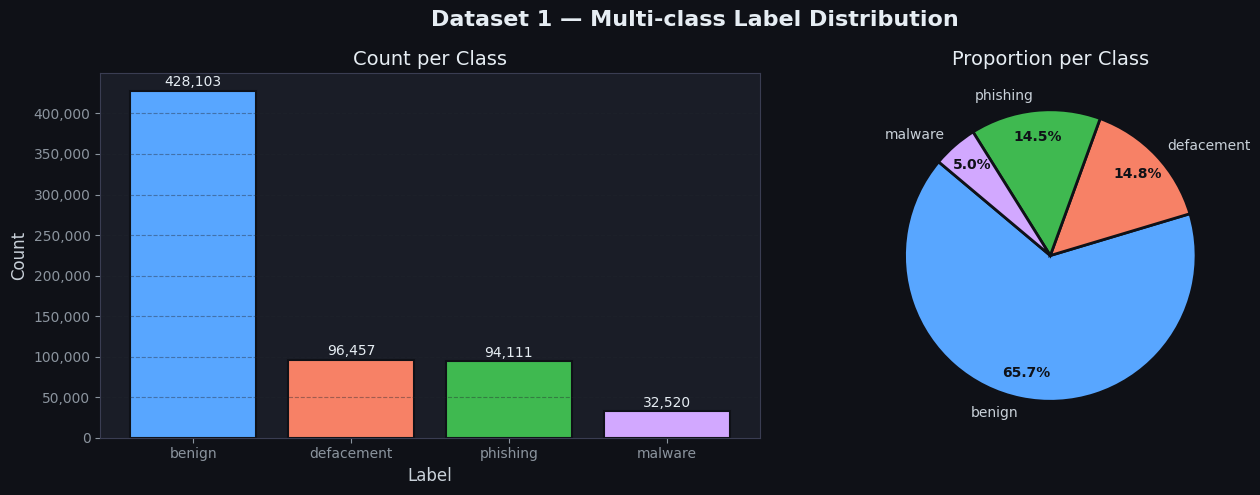


── URL Length — Dataset 1 ──
               count  mean   std   min   25%   50%    75%     max
type                                                             
benign      428103.0  57.7  44.3   6.0  31.0  46.0   71.0  2175.0
defacement   96457.0  86.3  41.9  17.0  55.0  81.0  105.0   327.0
malware      32520.0  56.5  28.4   7.0  33.0  49.0   76.0   378.0
phishing     94111.0  45.9  43.8   1.0  25.0  35.0   49.0  1779.0


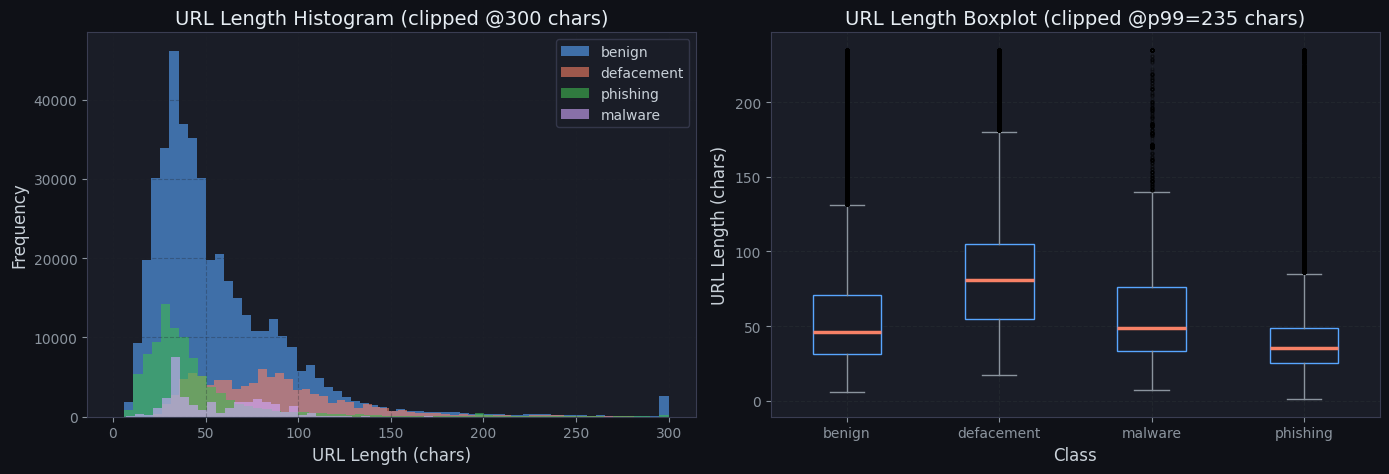

In [3]:
print("\n── EDA Dataset 1 ──")
print(df1['type'].value_counts())
print(f"Total: {len(df1)}")

label_counts1 = df1['type'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 1 — Multi-class Label Distribution', fontsize=16, color='#e6edf3', fontweight='bold')

ax = axes[0]
bars = ax.bar(label_counts1.index, label_counts1.values, color=PALETTE_4, edgecolor='#0f1117', linewidth=1.5)
ax.set_title('Count per Class', color='#e6edf3')
ax.set_xlabel('Label'); ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.4)
for bar, val in zip(bars, label_counts1.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
            f'{val:,}', ha='center', va='bottom', fontsize=10, color='#e6edf3')

wedges, texts, autotexts = axes[1].pie(
    label_counts1.values, labels=label_counts1.index, colors=PALETTE_4,
    autopct='%1.1f%%', startangle=140, pctdistance=0.82,
    wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for t in texts: t.set_color('#c9d1d9')
for at in autotexts: at.set_color('#0f1117'); at.set_fontweight('bold')
axes[1].set_title('Proportion per Class', color='#e6edf3')

plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds1_multiclass.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length DS1
df1['url_len'] = df1['url'].astype(str).apply(len)

print("\n── URL Length — Dataset 1 ──")
print(df1.groupby('type')['url_len'].describe().round(1))

# Clip @p99 để boxplot không bị méo bởi outlier của benign (max=2175) và phishing (max=1779)
p99_ds1 = df1['url_len'].quantile(0.99)
df1['url_len_clip'] = df1['url_len'].clip(upper=p99_ds1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 1 — URL Length by Class', fontsize=16, color='#e6edf3', fontweight='bold')

for label, color in zip(label_counts1.index, PALETTE_4):
    axes[0].hist(df1[df1['type'] == label]['url_len'].clip(upper=300),
                 bins=60, alpha=0.6, label=label, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)'); axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df1.boxplot(column='url_len_clip', by='type', ax=axes[1], patch_artist=True,
            boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
            medianprops=dict(color='#f78166', linewidth=2.5),
            whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
            flierprops=dict(marker='o', color='#d2a8ff', alpha=0.25, markersize=2))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99_ds1:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Class'); axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds1_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

4. EDA Dataset 2 (binary)


── EDA Dataset 2 ──
Label
0    94919
1    54807
Name: count, dtype: int64
Total: 149726


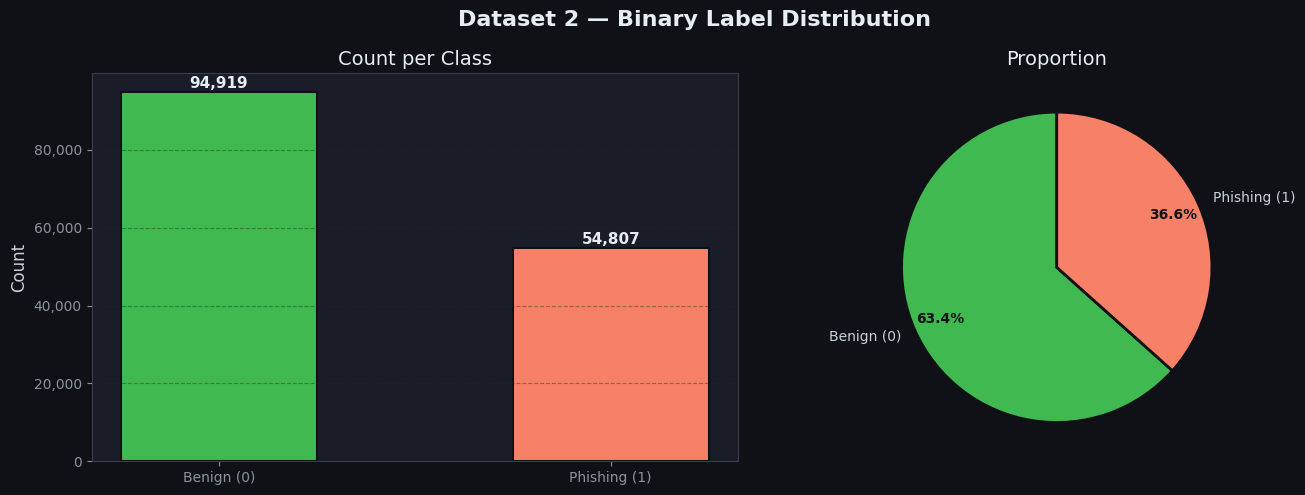


── URL Length — Dataset 2 ──
               count  mean    std   min   25%   50%   75%      max
Label                                                             
Benign(0)    94919.0  75.2   97.9  11.0  34.0  51.0  81.0   2031.0
Phishing(1)  54807.0  66.6  169.9  14.0  33.0  45.0  84.0  25523.0


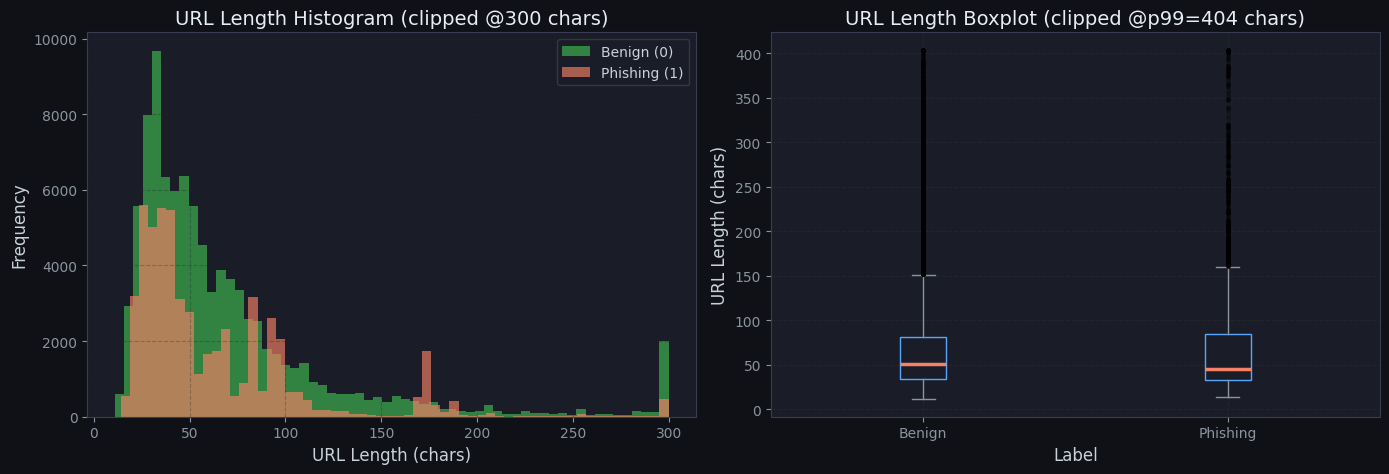

In [4]:
print("\n── EDA Dataset 2 ──")
label_counts2 = df2['Label'].value_counts().sort_index()
print(label_counts2)
print(f"Total: {len(df2)}")

df2['url_len'] = df2['URL'].astype(str).apply(len)
labels_text = ['Benign (0)', 'Phishing (1)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 2 — Binary Label Distribution', fontsize=16, color='#e6edf3', fontweight='bold')

bars = axes[0].bar(labels_text, label_counts2.values, color=PALETTE_2,
                   edgecolor='#0f1117', linewidth=1.5, width=0.5)
axes[0].set_title('Count per Class', color='#e6edf3')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
axes[0].grid(axis='y', alpha=0.4)
for bar, val in zip(bars, label_counts2.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f'{val:,}', ha='center', va='bottom', fontsize=11, color='#e6edf3', fontweight='bold')

wedges, texts, autotexts = axes[1].pie(
    label_counts2.values, labels=labels_text, colors=PALETTE_2,
    autopct='%1.1f%%', startangle=90, pctdistance=0.82,
    wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for t in texts: t.set_color('#c9d1d9')
for at in autotexts: at.set_color('#0f1117'); at.set_fontweight('bold')
axes[1].set_title('Proportion', color='#e6edf3')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds2_binary.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length DS2
print("\n── URL Length — Dataset 2 ──")
print(df2.groupby('Label')['url_len'].describe().round(1).rename(index={0:'Benign(0)', 1:'Phishing(1)'}))

# Clip ở p99 để boxplot không bị méo
p99 = df2['url_len'].quantile(0.99)
df2['url_len_clip'] = df2['url_len'].clip(upper=p99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Dataset 2 — URL Length Distribution by Label', fontsize=16, color='#e6edf3', fontweight='bold')

for lv, color, ls in zip([0, 1], PALETTE_2, labels_text):
    axes[0].hist(df2[df2['Label'] == lv]['url_len'].clip(upper=300),
                 bins=60, alpha=0.65, label=ls, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)')
axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df2['Label_str'] = df2['Label'].map({0: 'Benign', 1: 'Phishing'})
df2.boxplot(column='url_len_clip', by='Label_str', ax=axes[1], patch_artist=True,
            boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
            medianprops=dict(color='#f78166', linewidth=2.5),
            whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
            flierprops=dict(marker='o', color='#d2a8ff', alpha=0.25, markersize=2))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds2_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()


5. Binary Conversion (Dataset 1 Binary Label Version)


── Binary Conversion ──
         type  Label   count
0      benign      0  428103
1  defacement      1   96457
2     malware      1   32520
3    phishing      1   94111
Total: 651191


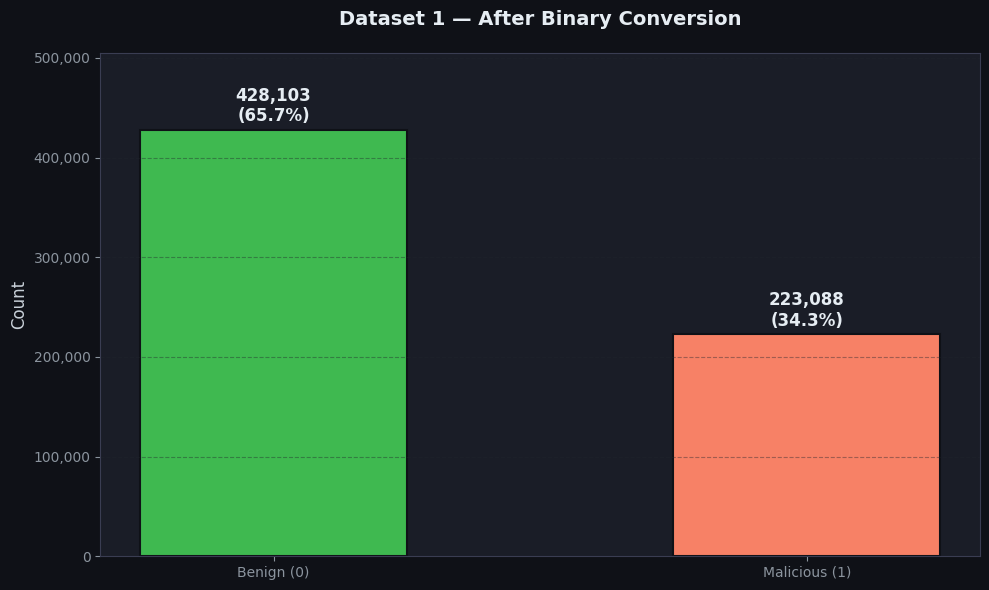

In [5]:
print("\n── Binary Conversion ──")
label_map = {'benign': 0, 'phishing': 1, 'defacement': 1, 'malware': 1}
df1_binary = df1[['url', 'type']].copy()
df1_binary['Label'] = df1_binary['type'].map(label_map)
print(df1_binary.groupby(['type', 'Label']).size().reset_index(name='count'))
print(f"Total: {len(df1_binary)}")

bin_dist = df1_binary['Label'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#0f1117')
ax.set_facecolor('#1a1d27')
bars = ax.bar(['Benign (0)', 'Malicious (1)'], bin_dist.values,
              color=PALETTE_2, edgecolor='#0f1117', linewidth=1.5, width=0.5)
ax.set_title('Dataset 1 — After Binary Conversion', color='#e6edf3', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.4)
# Tăng ylim để label không bị đẩy vào title
ax.set_ylim(0, max(bin_dist.values) * 1.18)
for bar, val in zip(bars, bin_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(bin_dist.values) * 0.01,
            f'{val:,}\n({val/len(df1_binary)*100:.1f}%)',
            ha='center', va='bottom', fontsize=12, color='#e6edf3', fontweight='bold')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_ds1_binary_after.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

6. Merge

In [6]:
print("\n── Merging ──")
ds1_clean = df1_binary[['url', 'Label']].rename(columns={'url': 'URL'})
ds1_clean = ds1_clean.copy(); ds1_clean['source'] = 'dataset1'
ds2_clean = df2[['URL', 'Label']].copy(); ds2_clean['source'] = 'dataset2'

df_merged = pd.concat([ds1_clean, ds2_clean], ignore_index=True)
print(f"After concat: {df_merged.shape[0]:,} rows")

n_before = len(df_merged)
df_merged_dedup = (
    df_merged
    .sort_values('Label', ascending=False)        # ← thêm dòng này
    .drop_duplicates(subset=['URL'], keep='first')
    .sort_index()
    .reset_index(drop=True)
)
n_after = len(df_merged_dedup)
print(f"Duplicates removed: {n_before - n_after:,}  |  Final: {n_after:,} rows")


── Merging ──
After concat: 800,917 rows
Duplicates removed: 30,087  |  Final: 770,830 rows


7. Normalized URL Scheme

In [7]:
print("\n── Normalize URL Scheme ──")

def normalize_url(url):
    url = str(url).strip()
    if not url.lower().startswith(('http://', 'https://', 'ftp://')):
        return 'http://' + url
    return url

df_merged_dedup = df_merged_dedup.copy()
no_scheme_before = (~df_merged_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs khong co scheme (truoc): {no_scheme_before:,} ({no_scheme_before/len(df_merged_dedup)*100:.1f}%)")

df_merged_dedup['URL'] = df_merged_dedup['URL'].apply(normalize_url)

no_scheme_after = (~df_merged_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs khong co scheme (sau)  : {no_scheme_after:,}")
print(f"  Da them 'http://' vao: {no_scheme_before - no_scheme_after:,} URLs")

# Re-dedup sau normalize — uu tien giu Label=1 (malicious) khi conflict
# Sort: Label giam dan → drop_duplicates giu dong dau tien → luon giu malicious
n_before_renorm = len(df_merged_dedup)
df_merged_dedup = (
    df_merged_dedup
    .sort_values('Label', ascending=False)       # Label=1 len truoc
    .drop_duplicates(subset=['URL'], keep='first') # giu dong dau (Label=1 neu conflict)
    .sort_index()                                  # restore thu tu ban dau
    .reset_index(drop=True)
)
n_removed_renorm = n_before_renorm - len(df_merged_dedup)
print(f"  Re-dedup sau normalize: removed {n_removed_renorm:,} | Final: {len(df_merged_dedup):,} rows")
print(f"  (Conflict URL duoc giu Label=1 — nguyen tac bao mat: URL da xac nhan doc hai giu nguyen)")



── Normalize URL Scheme ──
  URLs khong co scheme (truoc): 463,163 (60.1%)
  URLs khong co scheme (sau)  : 0
  Da them 'http://' vao: 463,163 URLs
  Re-dedup sau normalize: removed 3,948 | Final: 766,882 rows
  (Conflict URL duoc giu Label=1 — nguyen tac bao mat: URL da xac nhan doc hai giu nguyen)


8. EDA Merged


── EDA Merged Dataset ──
Label
0    499098
1    267784
Name: count, dtype: int64
Label
0    65.08
1    34.92
Name: count, dtype: float64
Total: 766882


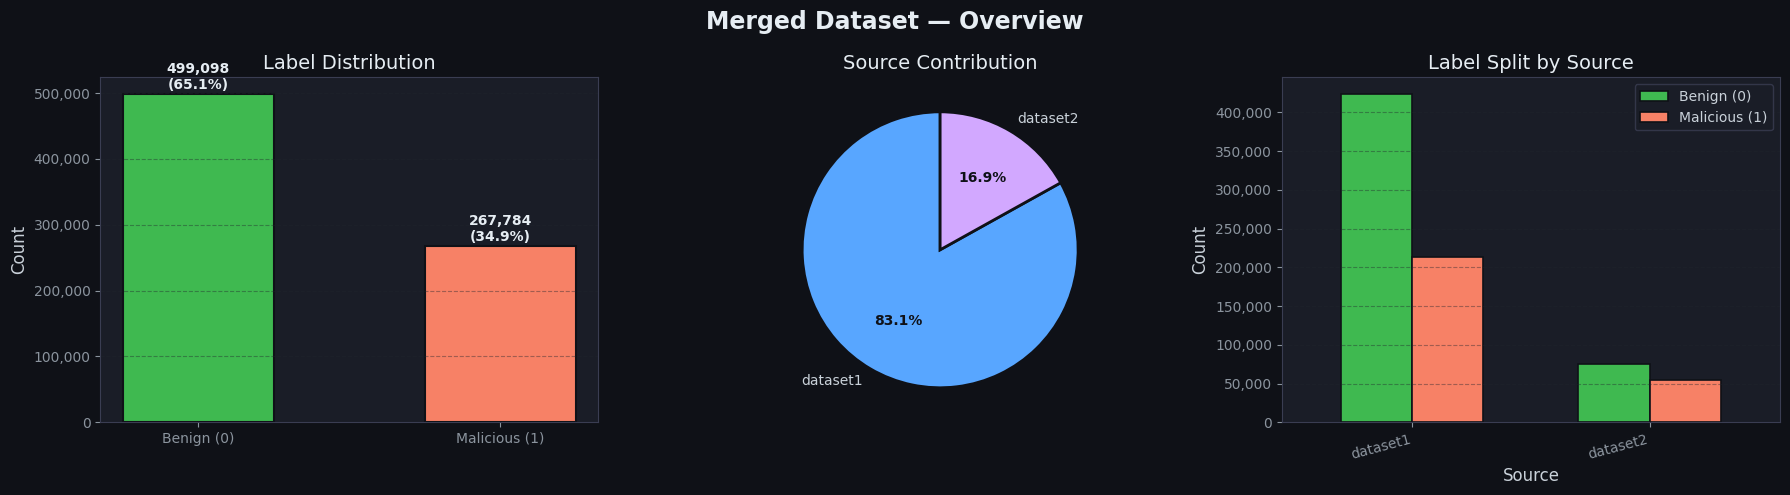


── URL Length — Merged Dataset ──
                 count  mean   std   min   25%   50%   75%      max
Label                                                              
Benign(0)     499098.0  67.5  58.2  11.0  39.0  54.0  80.0   2182.0
Malicious(1)  267784.0  66.3  86.4   8.0  35.0  51.0  85.0  25523.0


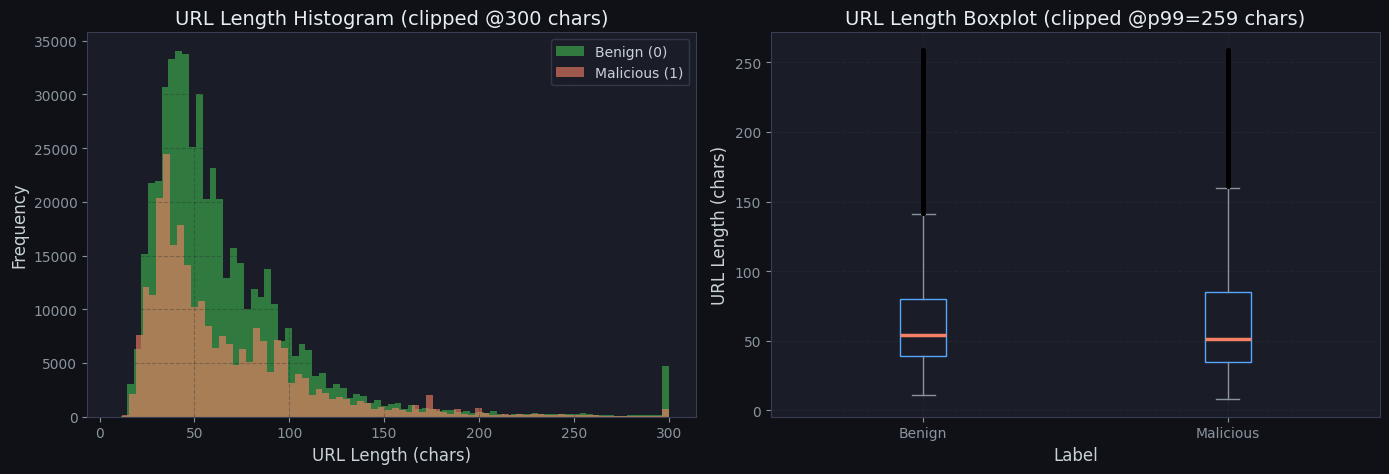

In [8]:
print("\n── EDA Merged Dataset ──")
merged_label_dist = df_merged_dedup['Label'].value_counts().sort_index()
print(merged_label_dist)
print((merged_label_dist / len(df_merged_dedup) * 100).round(2))
print(f"Total: {len(df_merged_dedup)}")

df_merged_dedup = df_merged_dedup.copy()
df_merged_dedup['url_len'] = df_merged_dedup['URL'].astype(str).apply(len)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Merged Dataset — Overview', fontsize=17, color='#e6edf3', fontweight='bold')

# Label dist
ax = axes[0]; ax.set_facecolor('#1a1d27')
bars = ax.bar(['Benign (0)', 'Malicious (1)'], merged_label_dist.values,
              color=PALETTE_2, edgecolor='#0f1117', linewidth=1.5, width=0.5)
ax.set_title('Label Distribution', color='#e6edf3')
ax.set_ylabel('Count')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.grid(axis='y', alpha=0.4)
for bar, val in zip(bars, merged_label_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
            f'{val:,}\n({val/len(df_merged_dedup)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, color='#e6edf3', fontweight='bold')

# Source pie
ax2 = axes[1]; ax2.set_facecolor('#1a1d27')
src = df_merged_dedup['source'].value_counts()
w, t, at = ax2.pie(src.values, labels=src.index, colors=['#58a6ff', '#d2a8ff'],
                   autopct='%1.1f%%', startangle=90,
                   wedgeprops=dict(edgecolor='#0f1117', linewidth=2))
for tt in t: tt.set_color('#c9d1d9')
for a in at: a.set_color('#0f1117'); a.set_fontweight('bold')
ax2.set_title('Source Contribution', color='#e6edf3')

# Label by source
ax3 = axes[2]; ax3.set_facecolor('#1a1d27')
cross = df_merged_dedup.groupby(['source', 'Label']).size().unstack(fill_value=0)
cross.plot(kind='bar', ax=ax3, color=PALETTE_2, edgecolor='#0f1117', linewidth=1.2, width=0.6)
ax3.set_title('Label Split by Source', color='#e6edf3')
ax3.set_xlabel('Source'); ax3.set_ylabel('Count')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=15, ha='right')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax3.grid(axis='y', alpha=0.4)
ax3.legend(['Benign (0)', 'Malicious (1)'], facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')

plt.tight_layout()
plt.savefig('../Reports/Images/eda_merged_overview.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

# URL length merged
print("\n── URL Length — Merged Dataset ──")
print(df_merged_dedup.groupby('Label')['url_len'].describe().round(1).rename(index={0:'Benign(0)', 1:'Malicious(1)'}))

p99_merged = df_merged_dedup['url_len'].quantile(0.99)
df_merged_dedup['url_len_clip'] = df_merged_dedup['url_len'].clip(upper=p99_merged)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Merged Dataset — URL Length Analysis', fontsize=16, color='#e6edf3', fontweight='bold')
for lv, color, ls in zip([0, 1], PALETTE_2, ['Benign (0)', 'Malicious (1)']):
    axes[0].hist(df_merged_dedup[df_merged_dedup['Label'] == lv]['url_len'].clip(upper=300),
                 bins=80, alpha=0.6, label=ls, color=color)
axes[0].set_title('URL Length Histogram (clipped @300 chars)', color='#e6edf3')
axes[0].set_xlabel('URL Length (chars)'); axes[0].set_ylabel('Frequency')
axes[0].legend(facecolor='#1a1d27', edgecolor='#3a3d52', labelcolor='#c9d1d9')
axes[0].grid(alpha=0.3)

df_merged_dedup['Label_str'] = df_merged_dedup['Label'].map({0: 'Benign', 1: 'Malicious'})
df_merged_dedup.boxplot(column='url_len_clip', by='Label_str', ax=axes[1], patch_artist=True,
                        boxprops=dict(facecolor='#1a1d27', color='#58a6ff'),
                        medianprops=dict(color='#f78166', linewidth=2.5),
                        whiskerprops=dict(color='#8b949e'), capprops=dict(color='#8b949e'),
                        flierprops=dict(marker='o', color='#d2a8ff', alpha=0.2, markersize=1.5))
axes[1].set_facecolor('#1a1d27')
axes[1].set_title(f'URL Length Boxplot (clipped @p99={p99_merged:.0f} chars)', color='#e6edf3')
axes[1].set_xlabel('Label'); axes[1].set_ylabel('URL Length (chars)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../Reports/Images/eda_merged_url_length.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()
plt.close()

10. Export

In [9]:
df_export = df_merged_dedup[['URL', 'Label', 'source']].reset_index(drop=True)
df_export.to_csv('../Data/Processed/merged_dataset.csv', index=False)
print(f"\nExported: merged_dataset.csv  ({df_export.shape[0]:,} rows)")
print("\nFinal Label Distribution:")
fd = df_export['Label'].value_counts().sort_index()
for k, v in fd.items():
    print(f"  {k} → {v:,} ({v/len(df_export)*100:.2f}%)")


Exported: merged_dataset.csv  (766,882 rows)

Final Label Distribution:
  0 → 499,098 (65.08%)
  1 → 267,784 (34.92%)


11. Dataset 1 — Multi-class + Normalize + Dedup

In [10]:
print("\n── Normalize URL Scheme (Dataset1) ──")

df1_dedup = df1.copy()
ds1_no_scheme_before = (~df1_dedup['url'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs khong co scheme (truoc): {ds1_no_scheme_before:,} ({ds1_no_scheme_before/len(df1_dedup)*100:.1f}%)")

df1_dedup['url'] = df1_dedup['url'].apply(normalize_url)

ds1_no_scheme_after = (~df1_dedup['url'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"  URLs khong co scheme (sau)  : {ds1_no_scheme_after:,}")
print(f"  Da them 'http://' vao: {ds1_no_scheme_before - ds1_no_scheme_after:,} URLs")

# Re-dedup sau normalize — uu tien giu Label=1 (malicious) khi conflict
# Sort: Label giam dan → drop_duplicates giu dong dau tien → luon giu malicious
ds1_n_before_renorm = len(df1_dedup)
priority_map = {'benign': 0, 'phishing': 1, 'defacement': 1, 'malware': 1}
df1_dedup['_priority'] = df1_dedup['type'].map(priority_map)
df1_dedup = (
    df1_dedup
    .sort_values('_priority', ascending=False)
    .drop_duplicates(subset=['url'], keep='first')
    .drop(columns=['_priority'])
    .reset_index(drop=True)
)
ds1_n_removed_renorm = ds1_n_before_renorm - len(df1_dedup)
print(f"  Re-dedup sau normalize: removed {ds1_n_removed_renorm:,} | Final: {len(df1_dedup):,} rows")
print(f"  (Conflict URL duoc giu Label=1 — nguyen tac bao mat: URL da xac nhan doc hai giu nguyen)")
print(f"\n  Label distribution sau clean (multi-class):")
vc_clean = df1_dedup['type'].value_counts()
for k, v in vc_clean.items():
    print(f"    {k:12s} → {v:,} ({v/len(df1_dedup)*100:.2f}%)")

# Export
# df1_dedup[['url', 'type']].to_csv('../Data/Processed/dataset1_clean.csv', index=False)
# print("\nExported: dataset1_clean.csv")
df1_dedup = df1_dedup.rename(columns={'url': 'URL', 'type': 'Label'})
df1_dedup[['URL', 'Label']].to_csv('../Data/Processed/dataset1_clean.csv', index=False)
print("\nExported: dataset1_clean.csv")




── Normalize URL Scheme (Dataset1) ──
  URLs khong co scheme (truoc): 463,192 (71.1%)
  URLs khong co scheme (sau)  : 0
  Da them 'http://' vao: 463,192 URLs
  Re-dedup sau normalize: removed 14,012 | Final: 637,179 rows
  (Conflict URL duoc giu Label=1 — nguyen tac bao mat: URL da xac nhan doc hai giu nguyen)

  Label distribution sau clean (multi-class):
    benign       → 424,134 (66.56%)
    defacement   → 95,308 (14.96%)
    phishing     → 94,092 (14.77%)
    malware      → 23,645 (3.71%)

Exported: dataset1_clean.csv


12. Dataset 2 — Binary + Normalize + Dedup

In [11]:
print("\n── Normalize URL Scheme (Dataset2) ──")

df2_dedup = df2.copy()
ds2_no_scheme_before = (~df2_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"URLs khong co scheme (truoc): {ds2_no_scheme_before:,} ({ds2_no_scheme_before/len(df2_dedup)*100:.1f}%)")

df2_dedup['URL'] = df2_dedup['URL'].apply(normalize_url)

ds2_no_scheme_after = (~df2_dedup['URL'].str.lower().str.startswith(
    ('http://', 'https://', 'ftp://'))).sum()
print(f"URLs khong co scheme (sau)  : {ds2_no_scheme_after:,}")
print(f"Da them 'http://' vao: {ds2_no_scheme_before - ds2_no_scheme_after:,} URLs")

dup_urls = df2_dedup[df2_dedup.duplicated(subset=['URL'], keep=False)]
print(f"Tổng URL bị duplicate: {dup_urls['URL'].nunique():,}")

# Kiểm tra conflict label
conflict = (
    dup_urls.groupby('URL')['Label']
    .nunique()
    .reset_index()
    .query('Label > 1')
)

print(f"URL duplicate có conflict label: {len(conflict):,}")
print(f"URL duplicate cùng label: {dup_urls['URL'].nunique() - len(conflict):,}")

# ── Investigate TRƯỚC khi dedup ──
url_counts = df2_dedup['URL'].value_counts()
dup_counts = url_counts[url_counts > 1]

print(f"\n[Before dedup]")
print(f"Unique URLs có duplicate  : {len(dup_counts):,}")
print(f"Tổng rows bị ảnh hưởng   : {dup_counts.sum():,}")
print(f"Rows sẽ bị xóa           : {dup_counts.sum() - len(dup_counts):,}")
print(f"\nPhân bố số lần lặp:")
print(dup_counts.value_counts().sort_index().head(20))
print(f"\nTop 10 URLs lặp nhiều nhất:")
print(dup_counts.head(10))

# ── Dedup sau khi đã investigate ──
ds2_n_before_renorm = len(df2_dedup)
df2_dedup = (
    df2_dedup
    .sort_values('Label', ascending=False)
    .drop_duplicates(subset=['URL'], keep='first')
    .sort_index()
    .reset_index(drop=True)
)
ds2_n_removed_renorm = ds2_n_before_renorm - len(df2_dedup)
print(f"\nRe-dedup: removed {ds2_n_removed_renorm:,} | Final: {len(df2_dedup):,} rows")

# Export
df2_dedup[['URL', 'Label']].to_csv('../Data/Processed/dataset2_clean.csv', index=False)
print("\nExported: dataset2_clean.csv")

print(f"\n  [Ghi chu] Top URLs lap nhieu nhat deu la robots.txt (benign)")
print(f"  → scraper co hard limit ~100 lan/domain, khong phai loi data")
print(f"  ✅ Khong co conflict label — drop an toan")


── Normalize URL Scheme (Dataset2) ──
URLs khong co scheme (truoc): 0 (0.0%)
URLs khong co scheme (sau)  : 0
Da them 'http://' vao: 0 URLs
Tổng URL bị duplicate: 2,090
URL duplicate có conflict label: 0
URL duplicate cùng label: 2,090

[Before dedup]
Unique URLs có duplicate  : 2,090
Tổng rows bị ảnh hưởng   : 22,040
Rows sẽ bị xóa           : 19,950

Phân bố số lần lặp:
count
2     954
3     264
4     127
5     110
6      67
7      44
8      41
9      30
10     29
11     17
12     15
13     21
14     12
15     18
16     15
17      9
18     12
19      7
20      9
21      6
Name: count, dtype: int64

Top 10 URLs lặp nhiều nhất:
URL
http://www.netflix.com/robots.txt       100
https://x.com/robots.txt                100
https://www.bilibili.com/robots.txt     100
http://www.yahoo.com/robots.txt         100
http://linktr.ee/robots.txt             100
https://europa.eu/robots.txt            100
https://www.bloomberg.com/robots.txt    100
https://mail.ru/robots.txt              100
https://